In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel("ApexPlanet_DataAnalytics_Dataset.xlsx")

In [3]:
df.head() #displays top 5 records

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [4]:
df.tail() #displays last 5 records

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
995,ORD100997,2025-11-07,CUST6410,Customer_301,61.0,Male,Gaya,Laptop,Electronics,9,35405.54,318649.86
996,ORD100998,2025-09-03,CUST7618,Customer_154,25.0,Male,Gaya,Shoes,Fashion,5,18454.65,92273.25
997,ORD100999,2025-09-30,CUST9544,Customer_140,62.0,Female,Hyderabad,Laptop,Electronics,9,12971.59,116744.31
998,ORD101000,2025-02-21,CUST9501,Customer_241,NaN,Male,Delhi,Mobile,Electronics,9,2879.01,25911.09
999,ORD101001,2025-04-23,CUST2714,Customer_98,58.0,Female,Gaya,Chair,Furniture,9,22493.87,202444.83


In [5]:
df.shape #displays no of rows and columns

(1000, 12)

In [6]:
df.columns #column names

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age',
       'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price',
       'Total_Sales'],
      dtype='object')

In [7]:
df.dtypes #column data type

Order_ID          object
Order_Date        object
Customer_ID       object
Customer_Name     object
Age              float64
Gender            object
City              object
Product           object
Category          object
Quantity           int64
Unit_Price       float64
Total_Sales      float64
dtype: object

In [8]:
data_dictionary = pd.DataFrame({
    "Column_Name": [
        "Order_ID", "Order_Date", "Customer_ID",
        "Customer_Name", "Age", "Gender", "City",
        "Product", "Category", "Quantity",
        "Unit_Price", "Total_Sales"
    ],

    "Data_Type": [
        "String", "Date", "String", "String",
        "Numeric", "Categorical", "Categorical",
        "Categorical", "Categorical", "Integer",
        "Float", "Float"
    ],

    "Description": [
        "Unique order reference",
        "Date of purchase",
        "Customer identification number",
        "Name of customer",
        "Age of customer",
        "Gender of customer",
        "Customer city",
        "Purchased product",
        "Product category",
        "Number of items purchased",
        "Price of one item",
        "Total purchase amount"
    ],

    "Business_Relevance": [
        "Identifies orders",
        "Helps analyze sales trends",
        "Identifies customers",
        "Helps understand customers",
        "Helps analyze age groups",
        "Helps analyze gender distribution",
        "Helps analyze location-based sales",
        "Identifies popular products",
        "Helps compare product categories",
        "Measures items sold",
        "Helps analyze product pricing",
        "Measures total revenue"
    ]
})

data_dictionary

,Column_Name,Data_Type,Description,Business_Relevance
0,Order_ID,String,Unique order reference,Identifies orders
1,Order_Date,Date,Date of purchase,Helps analyze sales trends
2,Customer_ID,String,Customer identification number,Identifies customers
3,Customer_Name,String,Name of customer,Helps understand customers
4,Age,Numeric,Age of customer,Helps analyze age groups
5,Gender,Categorical,Gender of customer,Helps analyze gender distribution
6,City,Categorical,Customer city,Helps analyze location-based sales
7,Product,Categorical,Purchased product,Identifies popular products
8,Category,Categorical,Product category,Helps compare product categories
9,Quantity,Integer,Number of items purchased,Measures items sold


In [9]:
data_dictionary.to_csv("Data_Dictionary.csv", index=False)

In [10]:
df.isnull().sum() #checking missing values

Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name     0
Age              20
Gender            0
City             13
Product           0
Category          0
Quantity          0
Unit_Price        0
Total_Sales       0
dtype: int64

In [12]:
(df.isnull().sum() / len(df)) * 100 #Calculates the missing-value percentage

Order_ID         0.0
Order_Date       0.0
Customer_ID      0.0
Customer_Name    0.0
Age              2.0
Gender           0.0
City             1.3
Product          0.0
Category         0.0
Quantity         0.0
Unit_Price       0.0
Total_Sales      0.0
dtype: float64

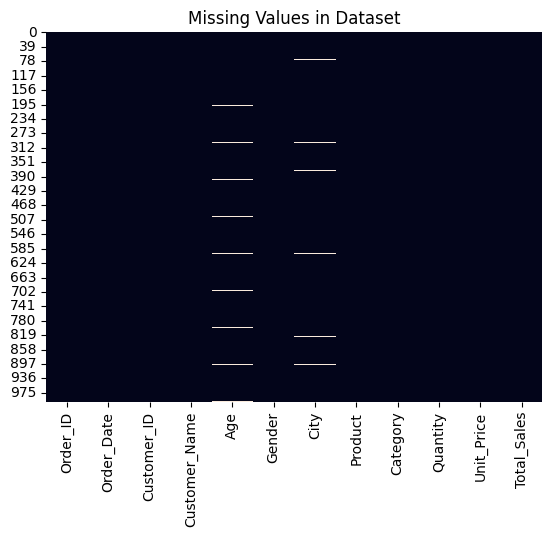

In [13]:
#Creates a visual representation
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values in Dataset")
plt.show()

In [14]:
df.duplicated().sum() #Checks duplicate records

np.int64(0)

In [16]:
df["Order_ID"].duplicated().sum() #checks whether order id is repeated

np.int64(8)

In [17]:
df["City"].value_counts(dropna=False)

City
Patna        135
Kolkata      133
Mumbai       131
Delhi        125
Hyderabad    125
Bengaluru    122
Gaya         117
Pune          99
NaN           13
Name: count, dtype: int64

In [20]:
df["Category"].value_counts()

Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64

In [21]:
df["Gender"].value_counts()

Gender
Male      511
Female    489
Name: count, dtype: int64

In [22]:
df["Product"].value_counts()

Product
Mobile    184
Book      178
Laptop    170
Chair     159
Shoes     156
Rice      153
Name: count, dtype: int64

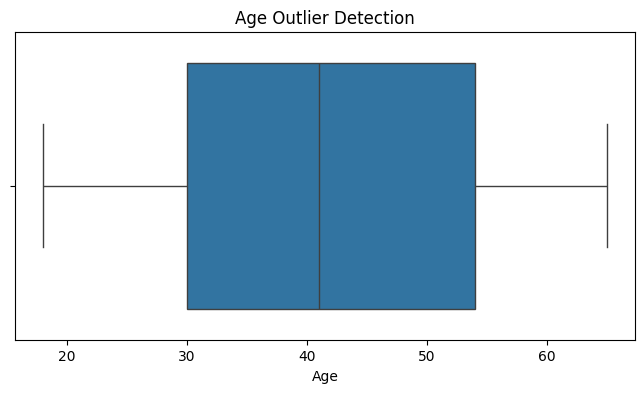

In [23]:
#checking outliers for age
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Age"])
plt.title("Age Outlier Detection")
plt.show()

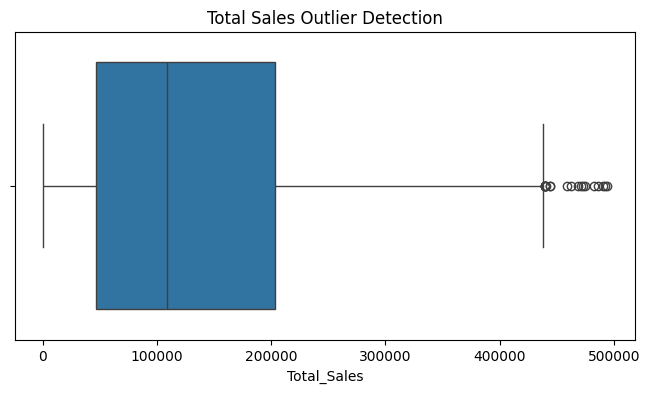

In [24]:
#checking outliers for total sales
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Total_Sales"])
plt.title("Total Sales Outlier Detection")
plt.show()

In [25]:
#makes a copy of origional dataset
cleaned_df = df.copy()

In [26]:
#filling the missing age values with median
median_age = cleaned_df["Age"].median()
cleaned_df["Age"] = cleaned_df["Age"].fillna(median_age)

In [27]:
cleaned_df["Age"].isnull().sum()

np.int64(0)

In [28]:
#Replace city missing value with unknown
cleaned_df["City"] = cleaned_df["City"].fillna("Unknown")

In [29]:
cleaned_df["City"].isnull().sum()

np.int64(0)

In [30]:
#Removing unnecessary spaces and standardize capitalization in text columns
text_columns = [
    "Gender",
    "City",
    "Product",
    "Category",
    "Customer_Name"
]

for col in text_columns:
    cleaned_df[col] = cleaned_df[col].astype(str).str.strip()

In [31]:
cleaned_df["Gender"] = cleaned_df["Gender"].str.title()

In [32]:
cleaned_df["City"] = cleaned_df["City"].str.title()

In [33]:
#Converting Order_Date into proper date format
cleaned_df["Order_Date"] = pd.to_datetime(
    cleaned_df["Order_Date"],
    errors="coerce"
)

In [34]:
cleaned_df["Order_Date"].dtype

dtype('<M8[ns]')

In [35]:
#Creating a flag to Handle repeated Order_ID values
cleaned_df["Duplicate_Order_ID_Flag"] = (
    cleaned_df["Order_ID"].duplicated(keep=False)
)

In [36]:
cleaned_df[
    cleaned_df["Duplicate_Order_ID_Flag"] == True
]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Duplicate_Order_ID_Flag
48,ORD100050,2025-10-03,CUST5523,Customer_432,41.0,Male,Pune,Chair,Furniture,9,30834.87,277513.83,True
118,ORD100050,2025-01-22,CUST3194,Customer_114,34.0,Male,Kolkata,Book,Education,2,25795.55,51591.10,True
238,ORD100050,2025-03-01,CUST8467,Customer_104,23.0,Male,Bengaluru,Book,Education,3,2860.83,8582.49,True
358,ORD100050,2025-02-11,CUST6467,Customer_181,24.0,Female,Pune,Rice,Grocery,7,45480.39,318362.73,True
478,ORD100050,2025-11-22,CUST8225,Customer_468,64.0,Male,Bengaluru,Rice,Grocery,8,38957.59,311660.72,True
598,ORD100050,2025-02-21,CUST8859,Customer_53,41.0,Male,Unknown,Laptop,Electronics,7,20144.84,141013.88,True
718,ORD100050,2025-11-06,CUST7824,Customer_190,31.0,Female,Mumbai,Rice,Grocery,4,42642.59,170570.36,True
838,ORD100050,2025-08-03,CUST5585,Customer_289,35.0,Male,Kolkata,Chair,Furniture,9,28747.47,258727.23,True
958,ORD100050,2025-02-09,CUST7188,Customer_89,62.0,Male,Bengaluru,Mobile,Electronics,1,34619.77,34619.77,True


In [37]:
#figure engineering 
#Extract Order Year
cleaned_df["Order_Year"] = (
    cleaned_df["Order_Date"].dt.year
)

In [38]:
#Extract Order Month
cleaned_df["Order_Month"] = (
    cleaned_df["Order_Date"].dt.month_name()
)

In [39]:
#Create Age Groups
cleaned_df["Age_Group"] = pd.cut(
    cleaned_df["Age"],
    bins=[0, 25, 35, 45, 55, 65],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65"
    ],
    include_lowest=True
)

In [43]:
#Validating the cleaned dataset
cleaned_df.isnull().sum()


Order_ID                   0
Order_Date                 0
Customer_ID                0
Customer_Name              0
Age                        0
Gender                     0
City                       0
Product                    0
Category                   0
Quantity                   0
Unit_Price                 0
Total_Sales                0
Duplicate_Order_ID_Flag    0
Order_Year                 0
Order_Month                0
Age_Group                  0
dtype: int64

In [42]:
cleaned_df.duplicated().sum()

np.int64(0)

In [44]:
cleaned_df.shape

(1000, 16)

In [45]:
#Checking sales calculation
(
    cleaned_df["Total_Sales"].round(2)
    ==
    (cleaned_df["Quantity"] * cleaned_df["Unit_Price"]).round(2)
).all()

np.True_

In [46]:
cleaned_df.to_csv(
    "Cleaned_Sales_Dataset.csv",
    index=False
)

In [47]:
cleaned_df.to_excel(
    "Cleaned_Sales_Dataset.xlsx",
    index=False
)

In [48]:
#Updating Data Dictionary
new_columns = pd.DataFrame({
    "Column_Name": [
        "Duplicate_Order_ID_Flag",
        "Order_Year",
        "Order_Month",
        "Age_Group"
    ],
    "Data_Type": [
        "Boolean", "Integer", "String", "Categorical"
    ],
    "Description": [
        "Identifies records with a repeated Order_ID",
        "Year extracted from Order_Date",
        "Month extracted from Order_Date",
        "Customer age category"
    ],
    "Business_Relevance": [
        "Helps investigate order ID quality",
        "Supports yearly sales analysis",
        "Supports monthly sales analysis",
        "Supports customer segmentation"
    ]
})

data_dictionary = pd.concat(
    [data_dictionary, new_columns],
    ignore_index=True
)

data_dictionary.to_csv(
    "Data_Dictionary.csv",
    index=False
)